<a href="https://colab.research.google.com/github/kylevalibia/IDX-Exchange-Data-Science/blob/main/03_baseline_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Read data from Google Drive
from google.colab import drive
drive.mount('/content/drive')
path = "/content/drive/MyDrive/Projects/IDX Exchange Data/"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [71]:
# Data comes from Notebook 2, contains all preprocessed data ready to model
x_train = pd.read_csv(path + "x_train.csv", low_memory=False)
x_test = pd.read_csv(path + "x_test.csv", low_memory=False)

# trainClosePrice = pd.read_csv(path + "trainClosePrice.csv", low_memory=False)
# testClosePrice = pd.read_csv(path + "testClosePrice.csv", low_memory=False)

# x_train["ClosePrice"] = trainClosePrice["ClosePrice"]
# x_test["ClosePrice"] = testClosePrice["ClosePrice"]

# calculated from Notebook 2
train_std = np.std(x_train["ActualClosePrice"])
train_mean = x_train["ActualClosePrice"].mean()

log_train_std = np.std(np.log1p(x_train["ActualClosePrice"]))
log_train_mean = np.log1p(x_train["ActualClosePrice"]).mean()

# Double check columns match Notebook 2
print(len(x_train.columns) == 506)
print(len(x_test.columns) == 506)

# Double check rows match Notebook 2
print(len(x_train) == 135201)
print(len(x_test) == 23301)

True
True
True
True


# Training Using Linear Regression

In [72]:
# Create validation set from test set
# Use 2026 03 as validation
x_test = x_test.copy()

x_valid = x_test[x_test['dataset'] == "CRMLSSold202603.csv"].drop(columns='dataset')
x_test = x_test[x_test['dataset'] == "CRMLSSold202604.csv"].drop(columns='dataset')
x_train = x_train.drop(columns='dataset')

print(x_valid.shape)
print(x_test.shape)

(11195, 505)
(12106, 505)


In [73]:
#x_train = x_train.drop(columns='dataset')

y_train = x_train["logClosePrice"]
y_valid = x_valid["logClosePrice"]
y_test = x_test["logClosePrice"]

actual_train_close_price = x_train["ActualClosePrice"]
actual_valid_close_price = x_valid["ActualClosePrice"]
actual_test_close_price = x_test["ActualClosePrice"]

x_train_model = x_train.drop(columns=["ClosePrice", "logClosePrice", "ActualClosePrice"])
x_valid_model = x_valid.drop(columns=["ClosePrice", "logClosePrice", "ActualClosePrice"])
x_test_model = x_test.drop(columns=["ClosePrice", "logClosePrice", "ActualClosePrice"])


R2: 0.7994517778159804
RMSE: $416149.47
MAE: $207529.13


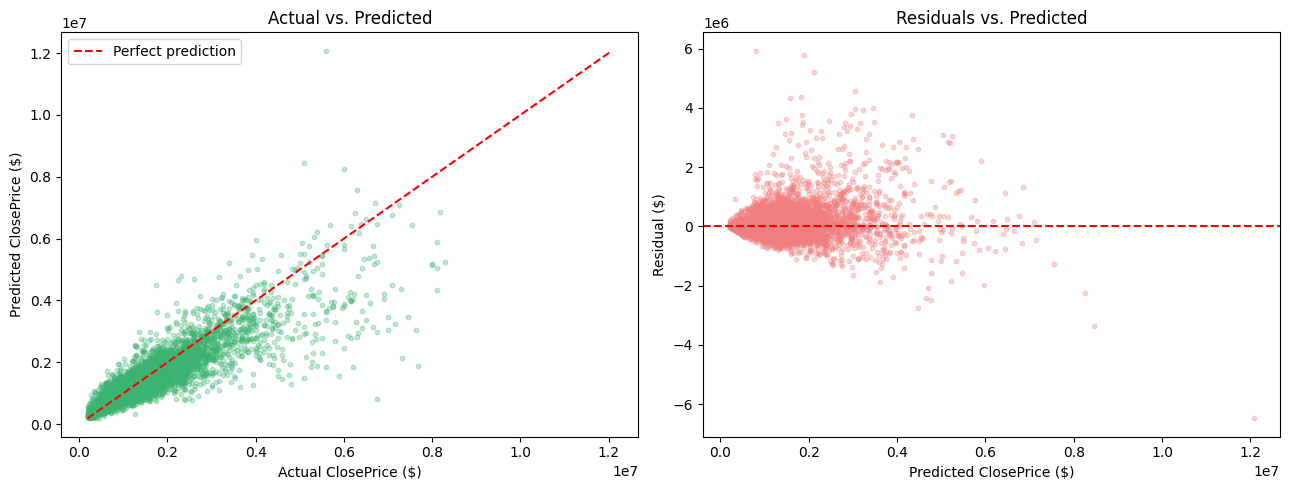

In [102]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


def predict_model(x_train, y_train, x_eval, actual_close, log_mean, log_std):

  model = LinearRegression()
  model.fit(x_train, y_train)

  pred_std = model.predict(x_eval)
  pred_dollars = np.exp(pred_std * log_std + log_mean)
  actual_dollars = np.asarray(actual_close)

  r2 = r2_score(actual_dollars, pred_dollars)
  rmse = np.sqrt(mean_squared_error(actual_dollars, pred_dollars))
  mae = mean_absolute_error(actual_dollars, pred_dollars)

  print(f"R2: {r2}")
  print(f"RMSE: ${round(rmse, 2)}")
  print(f"MAE: ${round(mae, 2)}")

  residuals = actual_dollars - pred_dollars

  fig, axes = plt.subplots(1, 2, figsize=(13, 5))

  # Actual vs. predicted
  axes[0].scatter(actual_dollars, pred_dollars, alpha = 0.3, s = 10, color = "mediumseagreen")
  lims = [min(actual_dollars.min(), pred_dollars.min()), max(actual_dollars.max(), pred_dollars.max())]

  axes[0].plot(lims, lims, "r--", label="Perfect prediction")
  axes[0].set_xlabel("Actual ClosePrice ($)")
  axes[0].set_ylabel("Predicted ClosePrice ($)")
  axes[0].set_title("Actual vs. Predicted")
  axes[0].legend()

  # Residuals vs. predicted, with a horizontal line at zero
  axes[1].scatter(pred_dollars, residuals, alpha = 0.3, s = 10, color = 'lightcoral')

  axes[1].axhline(0, color="r", linestyle="--")
  axes[1].set_xlabel("Predicted ClosePrice ($)")
  axes[1].set_ylabel("Residual ($)")
  axes[1].set_title("Residuals vs. Predicted")

  plt.tight_layout()
  plt.show()


predict_model(x_train_model, y_train, x_valid_model, actual_valid_close_price, log_train_mean, log_train_std)

The above is using ALL COLUMNS. Let's look at a select few columns.

In [96]:
x_train_model.columns

Index(['Latitude', 'Longitude', 'logLivingArea', 'logLotSizeSquareFeet',
       'BedroomsTotal', 'BathroomsTotalInteger', 'AgeAtSale', 'SaleYear',
       'City_29 Palms', 'City_Acton',
       ...
       'City_Winton', 'City_Woodland Hills', 'City_Woodside',
       'City_Wrightwood', 'City_Yorba Linda', 'City_Yuba City', 'City_Yucaipa',
       'City_Yucca Valley', 'City_infrequent_sklearn', 'LotSize_missing'],
      dtype='object', length=502)

R2: 0.33063257314421124
RMSE: $760277.66
MAE: $484896.94


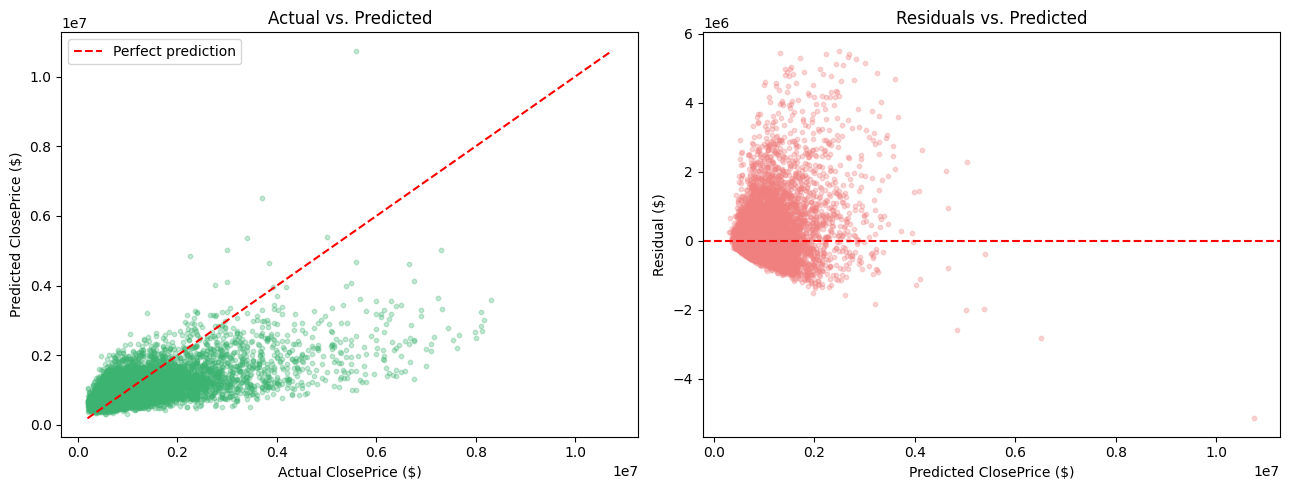

In [103]:
select_features = ["logLivingArea",
                   "logLotSizeSquareFeet",
                   'BedroomsTotal',
                   "BathroomsTotalInteger"]

predict_model(x_train_model[select_features], y_train, x_valid_model[select_features], actual_valid_close_price, log_train_mean, log_train_std)

R2: 0.49510173982939865
RMSE: $660300.88
MAE: $390126.95


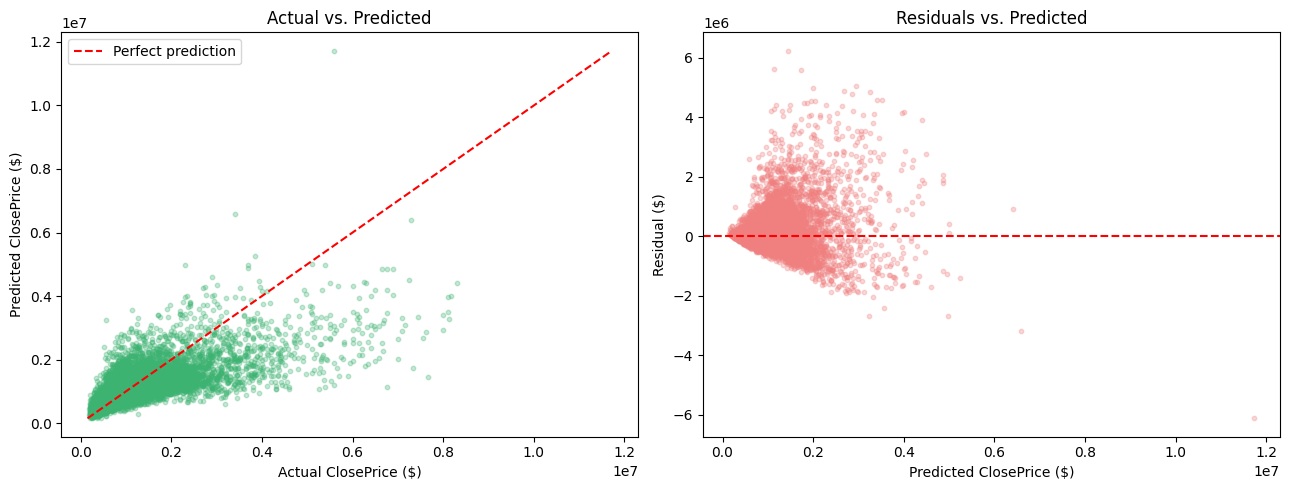

In [104]:
select_features = ["Latitude",
                   "Longitude",
                   "logLivingArea",
                   "logLotSizeSquareFeet",
                   'BedroomsTotal',
                   "BathroomsTotalInteger"]

predict_model(x_train_model[select_features], y_train, x_valid_model[select_features], actual_valid_close_price, log_train_mean, log_train_std)

R2: 0.518793072131475
RMSE: $644623.12
MAE: $369391.55


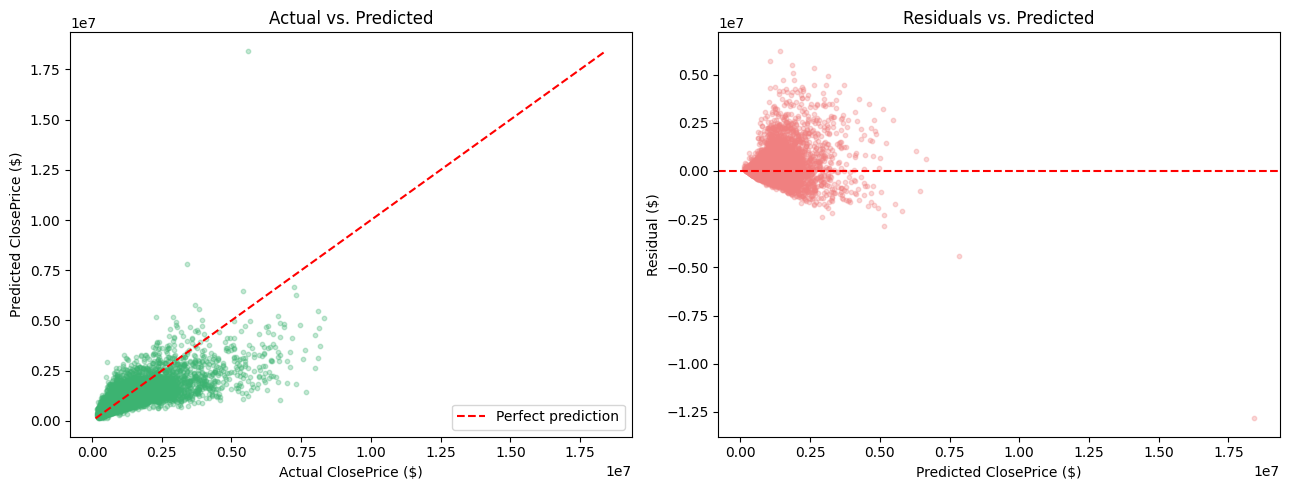

In [105]:
select_features = ["Latitude",
                   "Longitude",
                   "logLivingArea",
                   "logLotSizeSquareFeet",
                   'BedroomsTotal',
                   "BathroomsTotalInteger",
                   "AgeAtSale",
                   "SaleYear"]

predict_model(x_train_model[select_features], y_train, x_valid_model[select_features], actual_valid_close_price, log_train_mean, log_train_std)

R2: 0.5256017638735588
RMSE: $640046.42
MAE: $336524.44


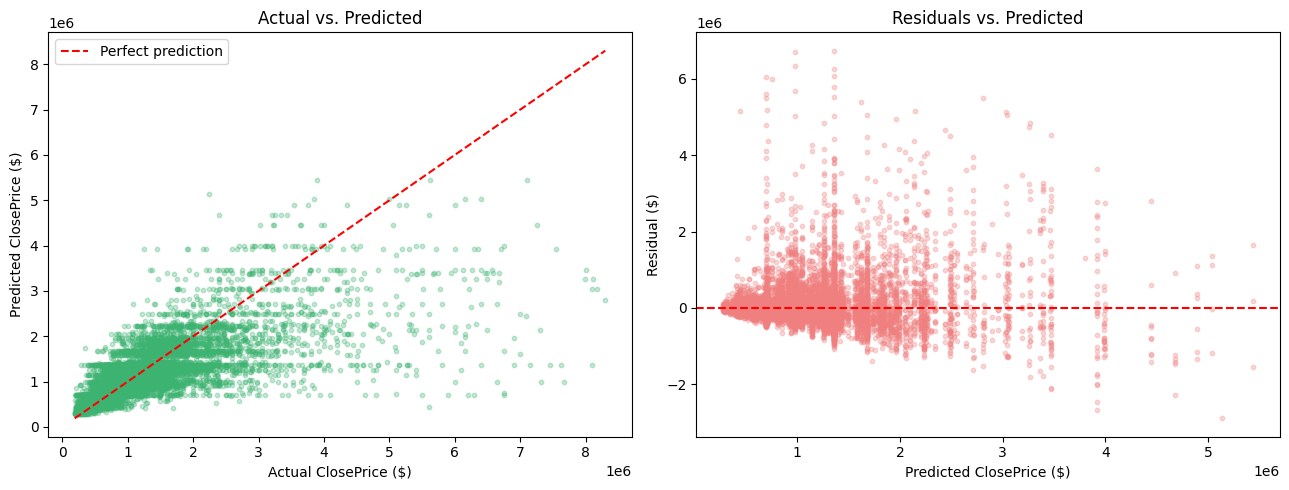

In [106]:
select_features = [c for c in x_train.columns if c.startswith("City_")]

predict_model(x_train_model[select_features], y_train, x_valid_model[select_features], actual_valid_close_price, log_train_mean, log_train_std)

Next week, look into ZIP code aggregates

Location by city looks to play a big factor in price prediction

--> `city price level`:
- get rid of the 500 city columns (so expensive)
- idea: converts all city columns into one numerical column, where the higher the number means the more expensive the city is (for example, Malibu gets a high number and Bakersfield gets a low number)
- fit on train, using k fold, and fit on out of fold values for each row

latitude/longitude will probably be redundant once city price level is obtained

that'll allow interaction with size, so i could obtain price per sqft by city (since that changes in between cities)

`SaleYear`, maybe instead try to get sale month to further analyze the pricing trends between months


# Test Set

R2: 0.8039546265343696
RMSE: $423696.58
MAE: $216334.04


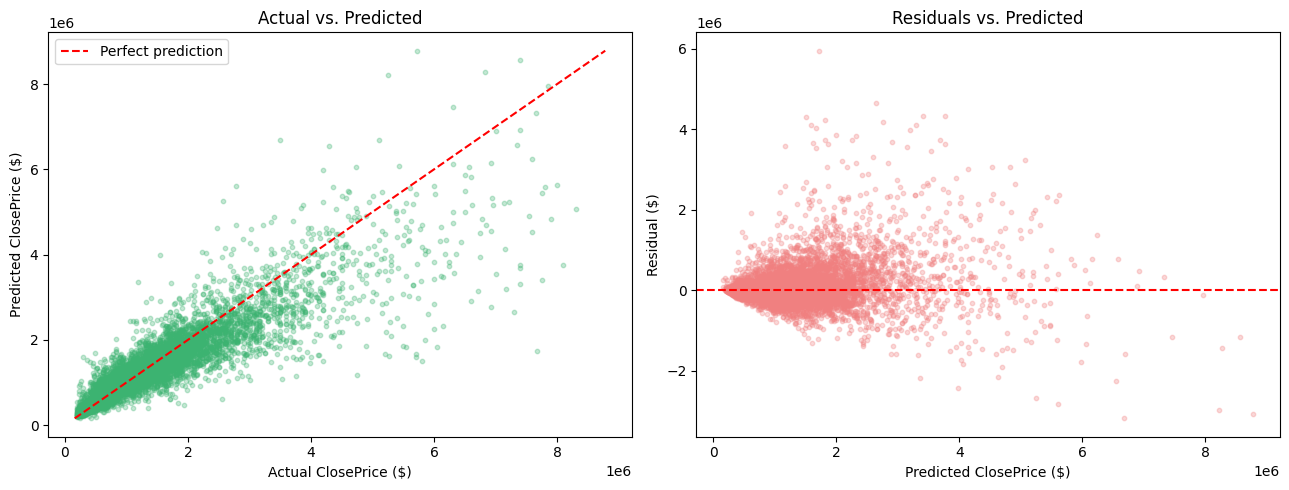

In [110]:
predict_model(x_train_model, y_train, x_test_model, actual_test_close_price, log_train_mean, log_train_std)

Plan for next week


create new columns and x_train, x_valid, and x_test sets (v2)

rerun linear regression on the above

run new models on decision tree and random forest